# Diabetes Risk Prediction — Data Cleaning, Preprocessing & EDA

**Academic Machine Learning Exam Project**  
**Phase 2:** Data Understanding, Data Cleaning, Missing Value Handling, and Exploratory Data Analysis (EDA).

---

## 1. Import Libraries
We begin by importing the core Python libraries required for data manipulation and visualization.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set plot style
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (8, 5)
plt.rcParams['font.size'] = 11

print("Libraries successfully imported!")

Libraries successfully imported!


## 2. Load Dataset
Load the raw Pima Indians Diabetes Dataset from the `data` directory.

In [4]:
# Load raw dataset
import os
data_path = 'data/diabetes.csv' if os.path.exists('data/diabetes.csv') else '../data/diabetes.csv'
df = pd.read_csv(data_path)
print(f"Successfully loaded dataset from: {data_path}")

Successfully loaded dataset from: ../data/diabetes.csv


## 3. Display First 5 Rows
Inspect the first 5 records to understand feature structures and values.

In [5]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## 4. Display Dataset Shape
Check the total number of patient records (rows) and attributes (columns).

In [6]:
print(f"Dataset Shape: {df.shape[0]} rows and {df.shape[1]} columns")

Dataset Shape: 768 rows and 9 columns


## 5. Display Column Names
List all 9 column feature names present in the dataset.

In [7]:
for i, col in enumerate(df.columns, 1):
    print(f"{i}. {col}")

1. Pregnancies
2. Glucose
3. BloodPressure
4. SkinThickness
5. Insulin
6. BMI
7. DiabetesPedigreeFunction
8. Age
9. Outcome


## 6. Display Data Types
Check the data type of each attribute to ensure compatibility with numerical operations.

In [8]:
df.dtypes

Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object

## 7. Check Missing Values
Verify standard `NaN` / null values across all columns.

In [9]:
df.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

## 8. Check Duplicate Rows
Check if there are any duplicate patient records.

In [10]:
duplicate_count = df.duplicated().sum()
print(f"Number of duplicate rows in dataset: {duplicate_count}")

Number of duplicate rows in dataset: 0


## 9. Generate Basic Statistical Summary
Examine descriptive statistics (mean, std, min, median, max) for numerical columns.

In [11]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


## 10. Analyze Target Variable (`Outcome`)
Understand the class distribution of the target variable `Outcome` (0 = Low Risk, 1 = High Risk).

In [12]:
outcome_counts = df['Outcome'].value_counts()
outcome_percentages = df['Outcome'].value_counts(normalize=True) * 100

summary_df = pd.DataFrame({
    'Count': outcome_counts,
    'Percentage (%)': outcome_percentages.round(2)
})
summary_df.index = ['Low Risk / No Diabetes (0)', 'High Risk / Diabetes (1)']
summary_df

,Count,Percentage (%)
Low Risk / No Diabetes (0),500,65.1
High Risk / Diabetes (1),268,34.9


## 11. Data Cleaning (Handling Biologically Zero Values)

### ⚠️ Explanation of Medical Zero Values:
In clinical datasets, certain physiological measurements cannot biologically be zero in a living patient:
- **Glucose**: A glucose level of 0 mg/dL is medically impossible.
- **BloodPressure**: A diastolic pressure of 0 mm Hg indicates absence of circulation.
- **SkinThickness**: Triceps skin fold thickness of 0 mm is biologically invalid.
- **Insulin**: Serum insulin level of 0 mu U/ml signifies unrecorded data.
- **BMI**: Body Mass Index of 0 kg/m² is physically impossible.

These zeroes represent **missing values** encoded as 0. We handle them by:
1. Replacing 0 with `np.nan` in these specific clinical columns.
2. Imputing `NaN` values using column **median** values (a robust measure that is resilient to outliers).

In [13]:
# Columns where 0 represents missing clinical data
zero_columns = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

print("Count of invalid zero values per column before cleaning:")
print((df[zero_columns] == 0).sum())

# Create a copy of the dataframe for cleaning
df_cleaned = df.copy()

# Replace 0 with NaN in physiological columns
df_cleaned[zero_columns] = df_cleaned[zero_columns].replace(0, np.nan)

print("\nMissing (NaN) values after replacing zeroes:")
print(df_cleaned.isnull().sum())

# Impute NaN values with median of each column
for col in zero_columns:
    median_val = df_cleaned[col].median()
    df_cleaned[col] = df_cleaned[col].fillna(median_val)

print("\nMissing (NaN) values after Median Imputation:")
print(df_cleaned.isnull().sum())

Count of invalid zero values per column before cleaning:
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

Missing (NaN) values after replacing zeroes:
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64

Missing (NaN) values after Median Imputation:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


In [14]:
# Save the cleaned dataset to CSV
output_dir = 'data' if os.path.exists('data') else '../data'
cleaned_csv_path = os.path.join(output_dir, 'cleaned_diabetes.csv')
df_cleaned.to_csv(cleaned_csv_path, index=False)
print(f"Cleaned dataset saved successfully to: {cleaned_csv_path}")

Cleaned dataset saved successfully to: ../data/cleaned_diabetes.csv


## 12. Exploratory Data Analysis (EDA Visualizations)
We now generate clean, clear visualizations to explore distributions and target relationships.

### Graph 1: Target Outcome Distribution

/var/folders/99/hbh7303s51qdmr_1dgxb9mj00000gn/T/ipykernel_94478/1017317560.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x='Outcome', data=df_cleaned, palette=['#2ecc71', '#e74c3c'])


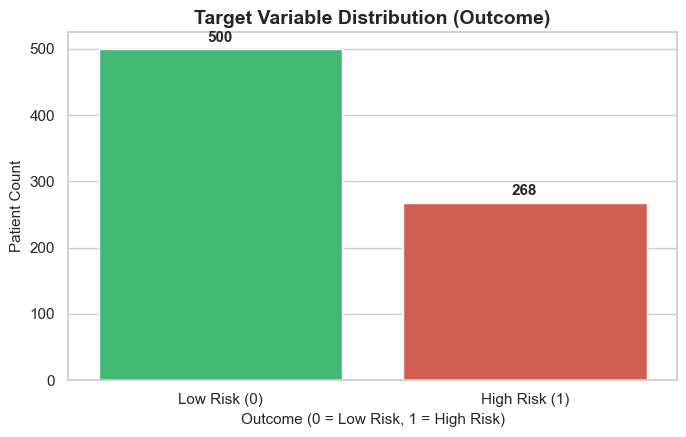

In [15]:
plt.figure(figsize=(7, 4.5))
ax = sns.countplot(x='Outcome', data=df_cleaned, palette=['#2ecc71', '#e74c3c'])
plt.title('Target Variable Distribution (Outcome)', fontsize=14, fontweight='bold')
plt.xlabel('Outcome (0 = Low Risk, 1 = High Risk)', fontsize=11)
plt.ylabel('Patient Count', fontsize=11)
plt.xticks([0, 1], ['Low Risk (0)', 'High Risk (1)'])

# Add count annotations above bars
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=11, fontweight='bold', xytext=(0, 3),
                textcoords='offset points')

plt.tight_layout()
plt.show()

This count plot displays the distribution of the target variable `Outcome`. Out of 768 total patients, 500 patients (~65.1%) are labeled as Low Risk (`Outcome = 0`) and 268 patients (~34.9%) are labeled as High Risk (`Outcome = 1`). This shows the dataset has moderate class imbalance.

### Graph 2: Age Distribution

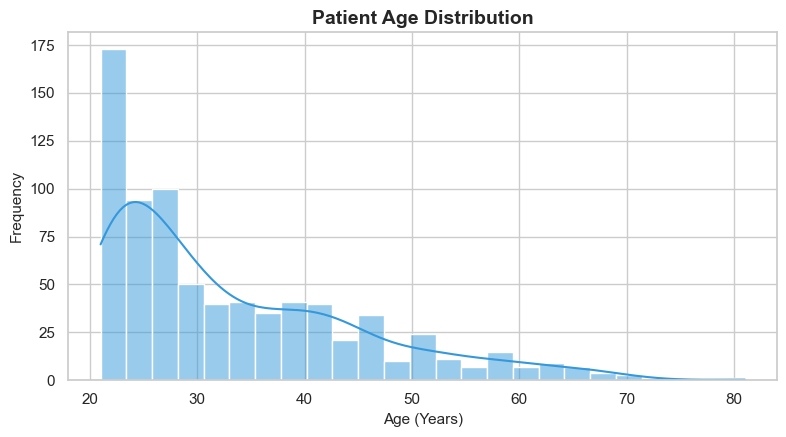

In [16]:
plt.figure(figsize=(8, 4.5))
sns.histplot(df_cleaned['Age'], kde=True, color='#3498db', bins=25)
plt.title('Patient Age Distribution', fontsize=14, fontweight='bold')
plt.xlabel('Age (Years)', fontsize=11)
plt.ylabel('Frequency', fontsize=11)
plt.tight_layout()
plt.show()

The Age distribution is right-skewed, indicating that the majority of patients in this dataset are young adults aged between 20 and 30 years old, with fewer older patients.

### Graph 3: Glucose Level Distribution

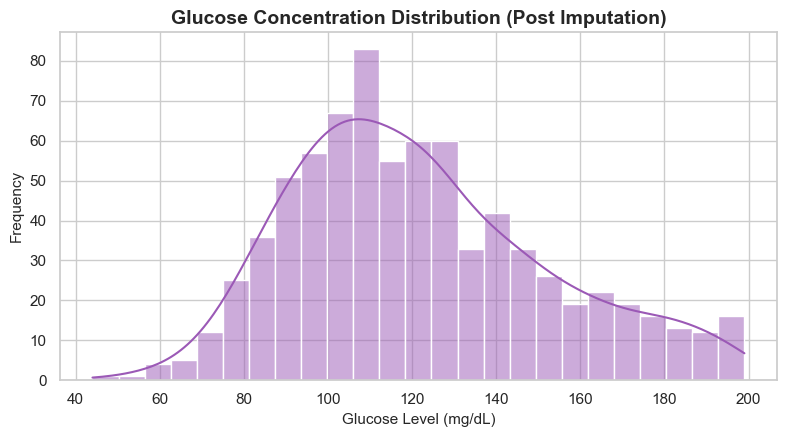

In [17]:
plt.figure(figsize=(8, 4.5))
sns.histplot(df_cleaned['Glucose'], kde=True, color='#9b59b6', bins=25)
plt.title('Glucose Concentration Distribution (Post Imputation)', fontsize=14, fontweight='bold')
plt.xlabel('Glucose Level (mg/dL)', fontsize=11)
plt.ylabel('Frequency', fontsize=11)
plt.tight_layout()
plt.show()

After replacing non-physiological zero values with the median glucose level, Glucose displays an approximately normal distribution centered around 120 mg/dL.

### Graph 4: BMI Distribution

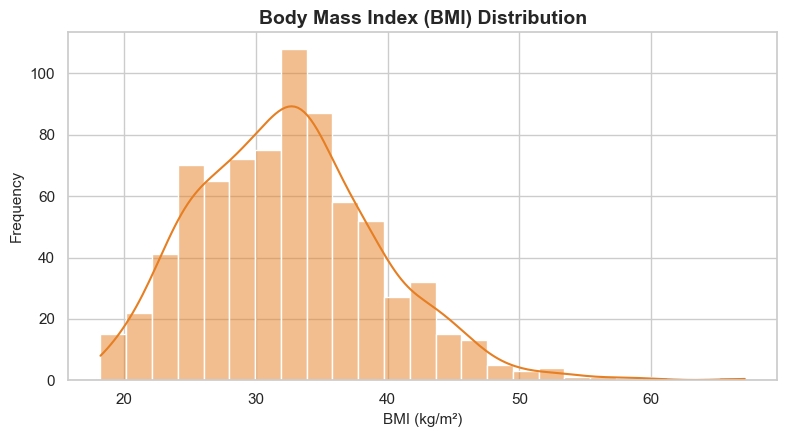

In [25]:
plt.figure(figsize=(8, 4.5))
sns.histplot(df_cleaned['BMI'], kde=True, color='#e67e22', bins=25)
plt.title('Body Mass Index (BMI) Distribution', fontsize=14, fontweight='bold')
plt.xlabel('BMI (kg/m²)', fontsize=11)
plt.ylabel('Frequency', fontsize=11)
plt.tight_layout()
plt.show()

The BMI distribution follows a bell-shaped normal curve peaking around 32 kg/m². Most patients in this study fall into the overweight or clinical obesity range (>25 kg/m²).

### Graph 5: BloodPressure Distribution

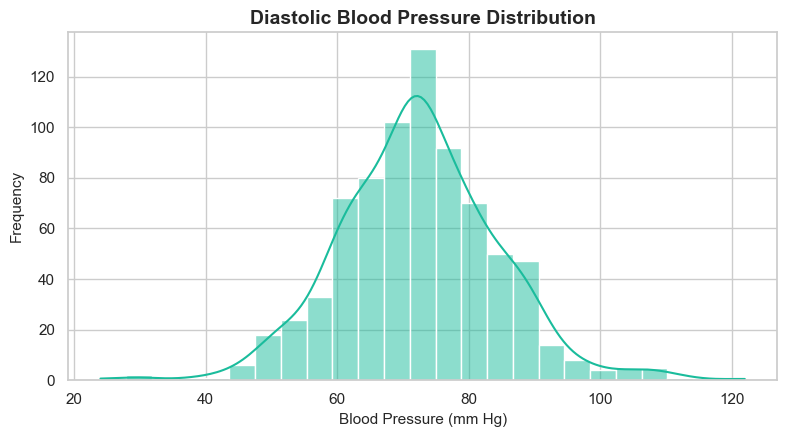

In [19]:
plt.figure(figsize=(8, 4.5))
sns.histplot(df_cleaned['BloodPressure'], kde=True, color='#1abc9c', bins=25)
plt.title('Diastolic Blood Pressure Distribution', fontsize=14, fontweight='bold')
plt.xlabel('Blood Pressure (mm Hg)', fontsize=11)
plt.ylabel('Frequency', fontsize=11)
plt.tight_layout()
plt.show()

Diastolic Blood Pressure shows a tight bell-shaped distribution centered around 72 mm Hg, which corresponds to normal diastolic resting pressure.

### Graph 6: Correlation Heatmap

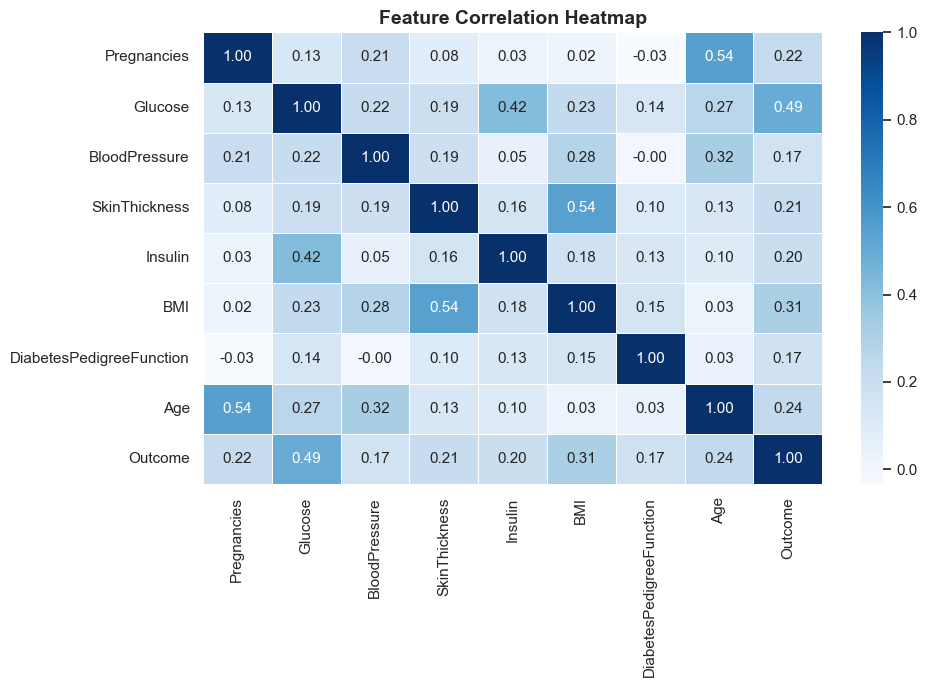

In [20]:
plt.figure(figsize=(10, 7))
correlation_matrix = df_cleaned.corr()
sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='Blues', linewidths=0.5)
plt.title('Feature Correlation Heatmap', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

The correlation heatmap measures linear associations between features and the target `Outcome`:
- **Glucose** shows the strongest positive correlation with `Outcome` (~0.49).
- **BMI** (~0.31) and **Age** (~0.24) also show moderate positive correlations with `Outcome`.
- **Pregnancies** correlates strongly with **Age** (~0.54), as expected.

## 13. Feature Relationships with Diabetes Outcome
Now we analyze how key physiological measurements differ between Low Risk and High Risk patient groups.

### Graph 7: Glucose Level vs Outcome

/var/folders/99/hbh7303s51qdmr_1dgxb9mj00000gn/T/ipykernel_94478/479992312.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Outcome', y='Glucose', data=df_cleaned, palette=['#2ecc71', '#e74c3c'])


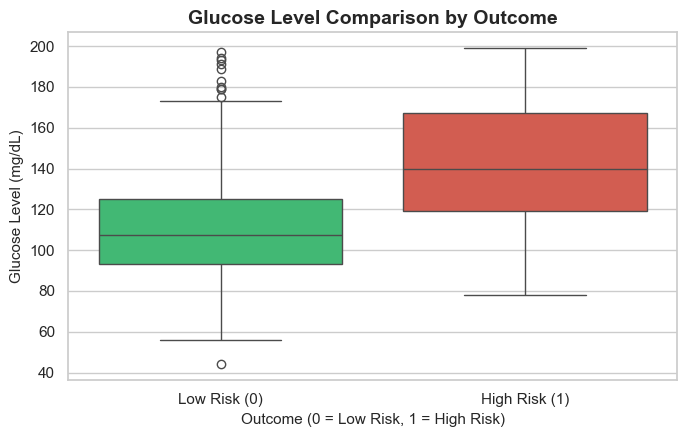

In [21]:
plt.figure(figsize=(7, 4.5))
sns.boxplot(x='Outcome', y='Glucose', data=df_cleaned, palette=['#2ecc71', '#e74c3c'])
plt.title('Glucose Level Comparison by Outcome', fontsize=14, fontweight='bold')
plt.xlabel('Outcome (0 = Low Risk, 1 = High Risk)', fontsize=11)
plt.ylabel('Glucose Level (mg/dL)', fontsize=11)
plt.xticks([0, 1], ['Low Risk (0)', 'High Risk (1)'])
plt.tight_layout()
plt.show()

**Explanation for Panelist:**  
Patients in the High Risk group (`Outcome = 1`) exhibit a noticeably higher median glucose level (~140 mg/dL) compared to the Low Risk group (~107 mg/dL). In this dataset, higher glucose concentrations are strongly associated with positive diabetes outcome labels.

### Graph 8: BMI vs Outcome

/var/folders/99/hbh7303s51qdmr_1dgxb9mj00000gn/T/ipykernel_94478/1166519661.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Outcome', y='BMI', data=df_cleaned, palette=['#2ecc71', '#e74c3c'])


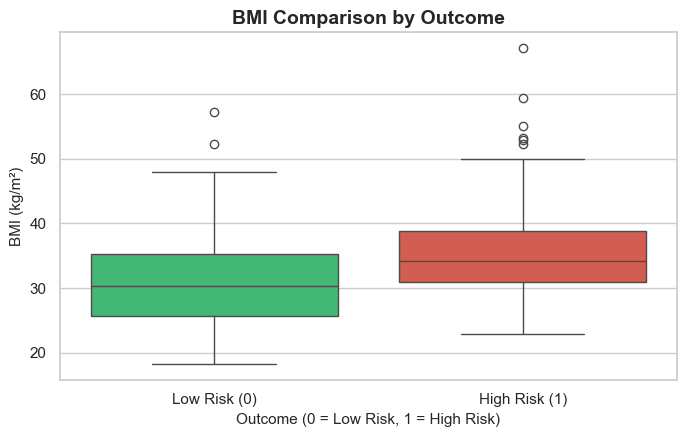

In [22]:
plt.figure(figsize=(7, 4.5))
sns.boxplot(x='Outcome', y='BMI', data=df_cleaned, palette=['#2ecc71', '#e74c3c'])
plt.title('BMI Comparison by Outcome', fontsize=14, fontweight='bold')
plt.xlabel('Outcome (0 = Low Risk, 1 = High Risk)', fontsize=11)
plt.ylabel('BMI (kg/m²)', fontsize=11)
plt.xticks([0, 1], ['Low Risk (0)', 'High Risk (1)'])
plt.tight_layout()
plt.show()

**Explanation for Panelist:**  
Patients labeled as High Risk (`Outcome = 1`) tend to have higher median BMI values (~34.2 kg/m²) than patients in the Low Risk group (~30.1 kg/m²). Higher BMI values are associated with a greater proportion of positive diabetes outcomes in this dataset.

### Graph 9: Age vs Outcome

/var/folders/99/hbh7303s51qdmr_1dgxb9mj00000gn/T/ipykernel_94478/1294727538.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Outcome', y='Age', data=df_cleaned, palette=['#2ecc71', '#e74c3c'])


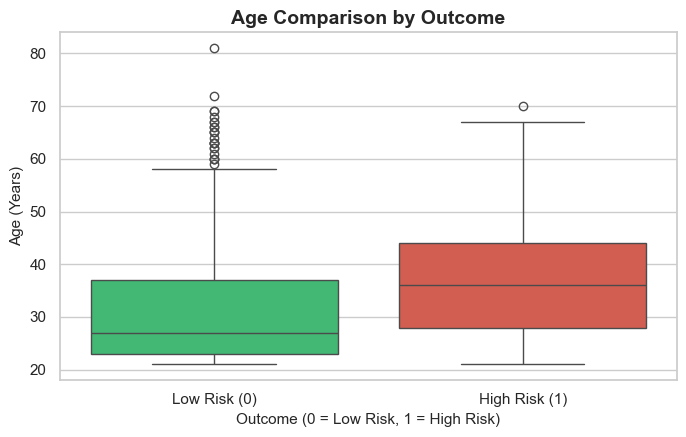

In [2]:
plt.figure(figsize=(7, 4.5))
sns.boxplot(x='Outcome', y='Age', data=df_cleaned, palette=['#2ecc71', '#e74c3c'])
plt.title('Age Comparison by Outcome', fontsize=14, fontweight='bold')
plt.xlabel('Outcome (0 = Low Risk, 1 = High Risk)', fontsize=11)
plt.ylabel('Age (Years)', fontsize=11)
plt.xticks([0, 1], ['Low Risk (0)', 'High Risk (1)'])
plt.tight_layout()
plt.show()

**Explanation for Panelist:**  
The median age for High Risk patients (~36 years) is higher than for Low Risk patients (~27 years). In this dataset, older age is associated with a higher proportion of positive diabetes outcomes.

## 14. Important Observations & Academic Summary

### Key Observations for Exam Presentation:
1. **Primary Risk Feature (Glucose):**  
   `Glucose` is the single most prominent predictor feature. Higher glucose values are strongly associated with a greater proportion of positive diabetes outcomes (`Outcome = 1`) in this dataset.

2. **Secondary Risk Features (BMI & Age):**  
   Both `BMI` and `Age` show significant positive associations with diabetes risk. Higher BMI and older age correlate with higher risk categories in this patient population.

3. **Biologically Invalid Zero Values Cleaned:**  
   Physiological zeroes in `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin`, and `BMI` were successfully identified as missing data and replaced using median imputation.

4. **Dataset Exported for Model Training:**  
   The clean dataset has been saved to `data/cleaned_diabetes.csv` and is ready for Phase 3 Model Training.